# 单通道：池化 trace 的闪烁统计

输入只有 `smTest_manual` 池化出来的 `TRACE_pooled/<组名>/traces_pooled.npz`，
**不碰影像**：不重新提取、不重新扣背景，只处理 trace 本身。

阈值法判 ON/OFF 的规则（这一本里实现，暂不进库）：

| 事件 | 判据 |
|---|---|
| 进 ON | 连续 `MIN_ON` 帧 > `ON_T`（本组数据 1 帧就算） |
| 进 OFF | 连续 `MIN_OFF` 帧 < `OFF_T`，OFF **从这段的第一帧算起**；不足 `MIN_OFF` 帧的暗坑算在 ON 里 |
| 开头 | 必须先进入 OFF 才开始统计；之前那段不完整的 ON 丢掉 |
| 结尾 | 最后一个没被 ON 接住的 OFF = 漂白；最后一个被窗口切断的 ON 同样是截断值 —— 都不统计 |

`ON_T` / `OFF_T` 分开给（迟滞），所以中间的灰带（100~150）不改变状态。

两个必须记住的事实：

1. **尾部 NaN**：池化为了对齐帧数，短的 trace 在后面补了 NaN。带着 NaN 跑
   `changepoint.segment` **不会报错**，但 `cumsum` 被污染，整条会被判成
   "一个暗段"。所以下面读盘时先按 `n_frames` 截断。
2. **每条的帧数不同**（1000 / 2000），任何统计都按条处理。


In [7]:
# `import smlm` 需要 Py_Smile 在 sys.path 上; notebook 放在子目录里时自己找一下
import pathlib
import sys

for _q in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_q / 'smlm' / '__init__.py').is_file():
        sys.path.insert(0, str(_q))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import smlm.trace as tr

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ======================= 输入 =======================
BASE_DIR = pathlib.Path(r"G:\SPARK\20261124")
POOL_DIR = BASE_DIR / 'TRACE_pooled'
GROUP = 'SPARK_6mW'                    # 先做这一组; 换组只改这里
POOLED = POOL_DIR / GROUP / 'traces_pooled.npz'

print('输入 :', POOLED)
print('存在 :', POOLED.is_file())


输入 : G:\SPARK\20261124\TRACE_pooled\SPARK_6mW\traces_pooled.npz
存在 : True


In [ ]:
def load_traces(path):
    """读 traces_pooled.npz -> (traces, files, dt, n_columns)。

    按 ``n_frames`` 截掉尾部的 NaN —— 否则后面的算法会静默拿到 NaN。
    """
    with np.load(path) as z:
        I = np.asarray(z['intensity'], np.float32)
        B = np.asarray(z['bg_flux'], np.float32)
        ids = np.asarray(z['emitter_id'], int)
        fid = np.asarray(z['file_id'], int)
        files = [str(s) for s in z['files']]
        nf = np.asarray(z['n_frames'], int)
        t_s = np.asarray(z['t_s'], float)
        dt = float(z['exposure_s'])
        n_col = int(I.shape[1])
    traces = []
    for i in range(len(ids)):
        n = int(nf[i])
        traces.append(dict(emitter_id=int(ids[i]), file_id=int(fid[i]),
                           file=files[fid[i]], frames=np.arange(n),
                           t_s=t_s[:n], intensity=I[i, :n],
                           bg_flux=B[i, :n]))
    return traces, files, dt, n_col


traces, files, dt, n_col = load_traces(POOLED)

n_frame = np.array([len(t['frames']) for t in traces])
peak = np.array([np.percentile(t['intensity'], 95) for t in traces])
em = np.array([t['emitter_id'] for t in traces])
fid = np.array([t['file_id'] for t in traces])

print(f'\n曝光 {dt:g} s, 池化数组宽 {n_col} 帧 (= 最长的一条, 短的补 NaN)')
print(f'共 {len(traces)} 条 trace, 帧数 {n_frame.min()}~{n_frame.max()}')
for k, name in enumerate(files):
    m = fid == k
    print(f'  [{k}] {name:<44} {m.sum():>4} 条, '
          f'{n_frame[m].max() if m.any() else 0} 帧')
print(f'\n95% 分位亮度: 中位 {np.median(peak):.0f}, '
      f'范围 {peak.min():.0f}~{peak.max():.0f}')


## 先看一眼数据

按 95% 分位亮度降序（先看亮的）。左列是扣背景后的信号 `intensity`，右列是
`bg_flux`。这组数据的 `intensity` 大部分帧接近 0，亮起来是稀疏的短闪 ——
所以下面按"单帧超过 150 就算 ON"来判。


In [ ]:
order = np.argsort(-peak)[:12]

fig = tr.plot_trace_fields(
    traces, indices=order,
    groups={'intensity': ('intensity',),
            'bg_flux': dict(fields=('bg_flux',), color='tab:red')},
    xlabel=f'Frame  ({dt:g} s/frame)',
    title=f'{GROUP}   最亮的 {len(order)} 条')
plt.show()


一屏看完所有 trace：按亮度排序的 `intensity` 热图（横轴帧、纵轴 trace）。
帧数不同的那些在右边是**空白**，不是 0。图存到
`TRACE_POOLED/<组名>/blink_heatmap.png`。


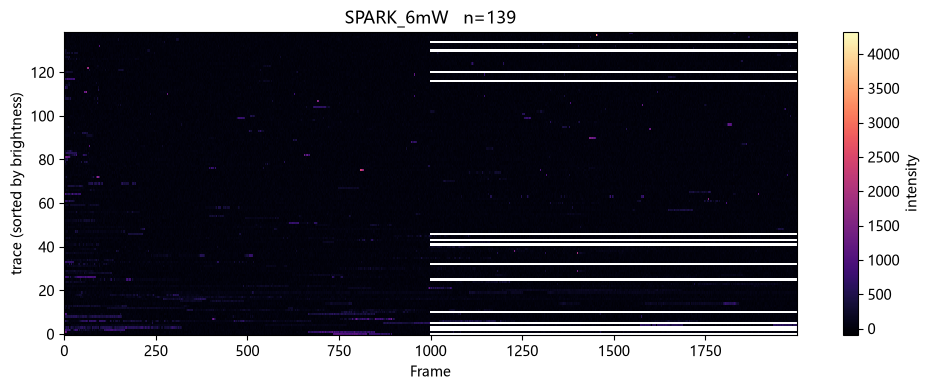

In [4]:
def heatmap(traces, title=None, figsize=(10, 4)):
    """按亮度排序的一屏热图; 帧数不同 -> 短的在右边留白。"""
    order = np.argsort([-np.percentile(t['intensity'], 95) for t in traces])
    T = max(len(t['intensity']) for t in traces)
    M = np.full((len(traces), T), np.nan)
    for r, i in enumerate(order):
        M[r, :len(traces[i]['intensity'])] = traces[i]['intensity']
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(M, aspect='auto', cmap='magma', origin='lower',
                   interpolation='nearest')
    ax.set_xlabel('Frame')
    ax.set_ylabel('trace (sorted by brightness)')
    ax.set_title(title or '')
    fig.colorbar(im, ax=ax, label='intensity')
    fig.tight_layout()
    return fig


heatmap(traces, title=f'{GROUP}   n={len(traces)}').savefig(
    POOLED.parent / 'blink_heatmap.png', dpi=150,
    bbox_inches='tight', facecolor='white')
plt.show()


## 阈值法：把一条 trace 切成 ON / OFF 段

`ON_T = 150`、`OFF_T = 100` 是两个**不同**的阈值（迟滞），中间那段灰带保持原状态，
免得噪声在阈值附近来回切。`MIN_OFF = 5` 决定"多长的暗坑才算真的 OFF"。

段表 `[(kind, start, stop), ...]` 是**连续**的：OFF 段的终点就是下一个 ON 段的起点。
最后一段永远是"没被接住"的那一段（漂白或窗口结束），统计时按规则丢掉。


In [5]:
# ======================= 阈值法参数 =======================
ON_T = 150.0           # 高于它 = ON
OFF_T = 100.0          # 连续这么低才算 OFF
MIN_OFF = 5            # ON -> OFF 需要的连续低帧数
MIN_ON = 1             # OFF -> ON 需要的连续高帧数 (这组数据 1 帧就算 ON)

DROP_TAIL_OFF = True   # 最后一个没被 ON 接住的 OFF (漂白) 不统计
DROP_TAIL_ON = True    # 最后一个被窗口切断的 ON 不统计


def _runs(flags, need):
    """连续 True 且长度 >= need 的段: 逐个产出 (start, stop)。"""
    i, n = 0, len(flags)
    while i < n:
        if flags[i]:
            j = i
            while j < n and flags[j]:
                j += 1
            if j - i >= need:
                yield i, j
            i = j
        else:
            i += 1


def segment_threshold(y, on_t=ON_T, off_t=OFF_T, min_off=MIN_OFF, min_on=MIN_ON):
    """阈值 + 迟滞 -> ``[(kind, start, stop), ...]``, kind 为 'on' / 'off'。

    开头必须先进入 OFF (连续 ``min_off`` 帧 < ``off_t``), 之前的丢掉;
    之后 ON / OFF 交替。返回的最后一段一定是没被接住的那段。
    从头到尾没进过 OFF 时返回 ``[]``。
    """
    y = np.asarray(y, float).reshape(-1)
    below, above = y < off_t, y > on_t

    start = next((a for a, _ in _runs(below, min_off)), None)
    if start is None:
        return []

    segs, state, seg_start, pos = [], 'off', start, start
    while pos < len(y):
        want, need = (above, min_on) if state == 'off' else (below, min_off)
        hit = next((a for a, _ in _runs(want[pos:], need)), None)
        if hit is None:
            segs.append((state, seg_start, len(y)))
            return segs
        hit += pos
        segs.append((state, seg_start, hit))
        state = 'on' if state == 'off' else 'off'
        seg_start = pos = hit
    segs.append((state, seg_start, len(y)))
    return segs


def counted_segments(segs, *, drop_tail_off=DROP_TAIL_OFF,
                     drop_tail_on=DROP_TAIL_ON):
    """去掉不该统计的段 (只看最后一段)。"""
    keep, last = [], len(segs) - 1
    for k, seg in enumerate(segs):
        kind = seg[0]
        if k == last and ((kind == 'off' and drop_tail_off)
                          or (kind == 'on' and drop_tail_on)):
            continue
        keep.append(seg)
    return keep


# 先在一条上试跑, 看看段切得对不对
_demo = traces[int(np.argmax([len(segment_threshold(t['intensity']))
                              for t in traces]))]
segs = segment_threshold(_demo['intensity'])
print(f"示例 #{_demo['emitter_id']}: {len(segs)} 段")
for kind, a, b in segs:
    print(f'  {kind:<3} {a:>5} ~ {b:>5}   {b - a:>4} 帧')


示例 #122: 33 段
  off     0 ~   334    334 帧
  on    334 ~   353     19 帧
  off   353 ~   370     17 帧
  on    370 ~   376      6 帧
  off   376 ~   387     11 帧
  on    387 ~   420     33 帧
  off   420 ~   434     14 帧
  on    434 ~   441      7 帧
  off   441 ~   480     39 帧
  on    480 ~   519     39 帧
  off   519 ~   532     13 帧
  on    532 ~   561     29 帧
  off   561 ~   603     42 帧
  on    603 ~   644     41 帧
  off   644 ~   691     47 帧
  on    691 ~   709     18 帧
  off   709 ~   782     73 帧
  on    782 ~   793     11 帧
  off   793 ~   823     30 帧
  on    823 ~   870     47 帧
  off   870 ~   899     29 帧
  on    899 ~   908      9 帧
  off   908 ~   931     23 帧
  on    931 ~   946     15 帧
  off   946 ~   956     10 帧
  on    956 ~   963      7 帧
  off   963 ~  1052     89 帧
  on   1052 ~  1068     16 帧
  off  1068 ~  1126     58 帧
  on   1126 ~  1133      7 帧
  off  1133 ~  1146     13 帧
  on   1146 ~  1171     25 帧
  off  1171 ~  2000    829 帧


## 全批统计

每条 trace 出：ON 次数、OFF 次数、ON/OFF 时间的中位数、ON 态的平均亮度
（用**被统计的**那些 ON 帧算），以及两个标记 —— 开头是否就处在 OFF（首段 OFF
被左截断）、结尾丢掉了哪一段。


In [8]:
def analyse(traces):
    """逐条跑阈值法 -> (DataFrame, ON 时间数组, OFF 时间数组), 时间单位 = 帧。"""
    rows, all_on, all_off, all_off_wo_head = [], [], [], []
    for t in traces:
        y = np.asarray(t['intensity'], float)
        segs = segment_threshold(y)
        keep = counted_segments(segs)
        on = np.array([b - a for kind, a, b in keep if kind == 'on'], int)
        off = np.array([b - a for kind, a, b in keep if kind == 'off'], int)
        px = np.concatenate([y[a:b] for kind, a, b in keep if kind == 'on']) \
            if on.size else np.array([])
        tail = segs[-1] if segs else None
        rows.append(dict(
            emitter_id=t['emitter_id'],
            fov=t['file'].split('0p1S_')[-1].replace('_trace', ''),
            n_frames=len(y),
            n_on=on.size, n_off=off.size,
            on_med=float(np.median(on)) if on.size else np.nan,
            off_med=float(np.median(off)) if off.size else np.nan,
            bright=float(px.mean()) if px.size else np.nan,
            off_at_start=bool(segs and segs[0][1] == 0),
            tail_seg=f'{tail[0]}[{tail[2] - tail[1]}]' if tail else '',
        ))
        all_on += on.tolist()
        all_off += off.tolist()
        all_off_wo_head += off[1:].tolist()      # 每条的首个 OFF 是左截断的
    return (pd.DataFrame(rows), np.array(all_on, int), np.array(all_off, int),
            np.array(all_off_wo_head, int))


df, ON, OFF, OFF_NO_HEAD = analyse(traces)
print(f'有 ON 事件的 trace : {(df.n_on > 0).sum()} / {len(df)}')
print(f'事件总数           : ON {ON.size}, OFF {OFF.size}')
for name, v in (('ON', ON), ('OFF', OFF)):
    if v.size:
        print(f'{name:<3} 时间 (帧): 中位 {np.median(v):6.1f}  '
              f'均值 {v.mean():7.2f}  最大 {v.max():5d}  '
              f'[{np.median(v) * dt:.2f} s 中位]')
print(f'开头就在 OFF 的条数: {int(df.off_at_start.sum())}  '
      f'(这些的首个 OFF 被左截断)')
print('结尾丢掉的段      :', df.tail_seg.str.split('[').str[0].value_counts().to_dict(),
      ' (off = 漂白/结束, on = 窗口切断)')
print(f'OFF 时间中位 (含每条首个 OFF): {np.median(OFF):.0f} 帧; '
      f'不含首个 OFF: {np.median(OFF_NO_HEAD):.0f} 帧 '
      f'(首个 OFF 起点就在第 0 帧的有 {int(df.off_at_start.sum())} 条)')
print(f'ON 态平均亮度     : 中位 {np.nanmedian(df.bright):.0f} '
      f'(有 ON 的条数 {int(df.bright.notna().sum())})')
df.sort_values("n_on", ascending=False).head(10)


有 ON 事件的 trace : 136 / 139
事件总数           : ON 545, OFF 547
ON  时间 (帧): 中位    4.0  均值   14.99  最大   304  [0.40 s 中位]
OFF 时间 (帧): 中位   93.0  均值  270.61  最大  1953  [9.30 s 中位]
开头就在 OFF 的条数: 92  (这些的首个 OFF 被左截断)
结尾丢掉的段      : {'off': 137, 'on': 2}  (off = 漂白/结束, on = 窗口切断)
OFF 时间中位 (含每条首个 OFF): 93 帧; 不含首个 OFF: 69 帧 (首个 OFF 起点就在第 0 帧的有 92 条)
ON 态平均亮度     : 中位 285 (有 ON 的条数 136)


,emitter_id,fov,n_frames,n_on,n_off,on_med,off_med,bright,off_at_start,tail_seg
112,122,2000frames_fov4,2000,16,16,17.0,29.5,165.450618,True,off[829]
46,77,2000frames_fov3,2000,14,14,2.0,22.0,156.994467,False,off[1188]
115,131,2000frames_fov4,2000,14,14,51.5,14.5,261.564167,False,off[270]
40,46,2000frames_fov3,2000,13,13,17.0,47.0,148.256342,True,off[388]
31,64,2000frames_fov2,2000,12,12,3.0,57.0,151.623894,True,off[79]
82,58,2000frames_fov4,2000,12,12,1.0,79.0,188.834657,True,off[359]
55,97,2000frames_fov3,2000,12,12,5.5,16.5,154.388936,True,off[835]
88,72,2000frames_fov4,2000,10,10,1.5,121.5,411.179911,True,off[110]
7,55,1000frames_fov1,1000,9,9,2.0,14.0,438.731116,True,off[810]
54,96,2000frames_fov3,2000,9,9,6.0,84.0,258.974925,True,off[894]


### 画出来核对

绿底 = 计入统计的 ON 段，蓝底 = 计入统计的 OFF 段，红斜纹 = 最后那段被丢掉的
（漂白 / 窗口切断），虚线是 150 / 100 两个阈值。


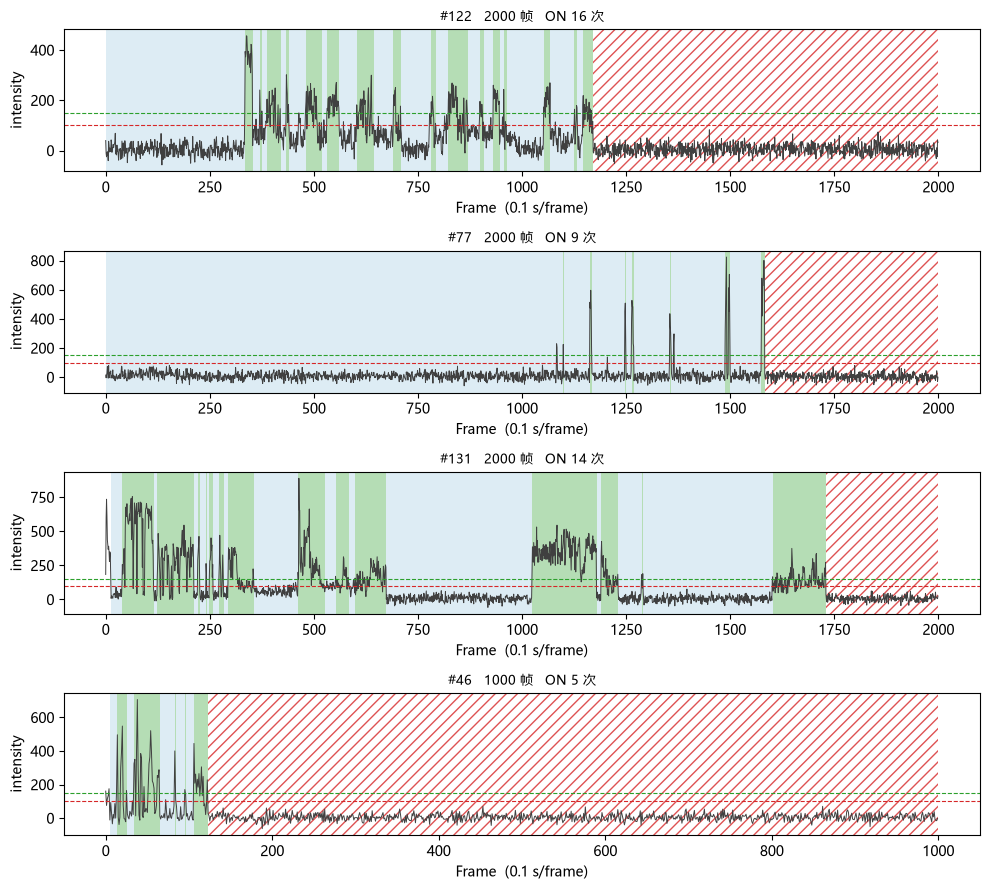

In [ ]:
def draw_segments(ax, y, segs, keep, *, dt=1.0, title='', xlim=None):
    x = np.arange(len(y))
    ax.plot(x, y, lw=0.7, color='0.25')
    for kind, a, b in segs:
        kept = (kind, a, b) in keep
        if kept:
            ax.axvspan(a, b, color='#2ca02c' if kind == 'on' else '#9ecae1',
                       alpha=0.35, lw=0)
        else:
            ax.axvspan(a, b, facecolor='none', edgecolor='tab:red',
                       hatch='///', lw=0, alpha=0.8)
    ax.axhline(ON_T, color='tab:green', ls='--', lw=0.8)
    ax.axhline(OFF_T, color='tab:red', ls='--', lw=0.8)
    ax.set_xlabel(f'Frame  ({dt:g} s/frame)')
    ax.set_ylabel('intensity')
    ax.set_title(title, fontsize=9)
    if xlim:
        ax.set_xlim(*xlim)


# 取 ON 次数最多的前 N_TOP 条, 全长
N_TOP = 4              # 想多看几条就改这里

pick = df.sort_values('n_on', ascending=False).head(N_TOP).emitter_id.values
fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.3 * len(pick)),
                         sharex=False, squeeze=False)
for ax, eid in zip(axes.ravel(), pick):
    t = traces[int(np.flatnonzero(em == eid)[0])]
    y = np.asarray(t['intensity'], float)
    segs = segment_threshold(y)
    draw_segments(ax, y, segs, counted_segments(segs), dt=dt,
                  title=f'#{eid}   {len(y)} 帧   '
                        f'ON {int((df.n_on[df.emitter_id == eid]).iloc[0])} 次')
fig.tight_layout()
plt.show()



### ON / OFF 时间分布

两个都用线性横轴（帧）。ON 的横轴截到 40 帧，否则 1~5 帧的峰会被长尾压平。


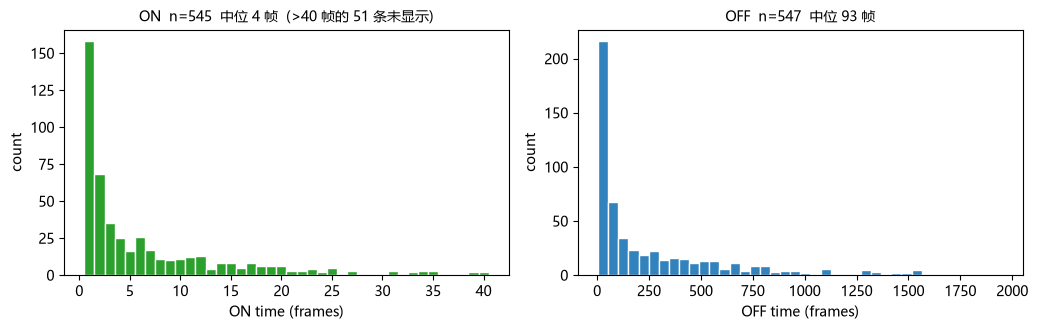

ON  时间 (帧) 分位 10/50/90: [ 1.   4.  38.2]
OFF 时间 (帧) 分位 10/50/90: [  9.   93.  772.6]
  (去掉每条首个 OFF 后)     : [  9.  69. 531.]
换算成秒 (×0.1): ON 中位 0.40 s, OFF 中位 9.30 s


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

ax = axes[0]
v = ON
hi = 40                      # 长 ON 很少, 截一下才看得清 1~5 帧的峰
n_far = int((v > hi).sum())
ax.hist(v[v <= hi], bins=np.arange(0.5, hi + 1.5, 1.0), color='#2ca02c',
        edgecolor='white')
ax.set_xlabel('ON time (frames)')
ax.set_ylabel('count')
ax.set_title(f'ON  n={v.size}  中位 {np.median(v):.0f} 帧'
             + (f'  (>{hi} 帧的 {n_far} 条未显示)' if n_far else ''),
             fontsize=10)

ax = axes[1]
v = OFF
ax.hist(v, bins=40, color='#3182bd', edgecolor='white')
ax.set_xlabel('OFF time (frames)')
ax.set_ylabel('count')
ax.set_title(f'OFF  n={v.size}  中位 {np.median(v):.0f} 帧', fontsize=10)

fig.tight_layout()
plt.show()

print('ON  时间 (帧) 分位 10/50/90:', np.percentile(ON, [10, 50, 90]))
print('OFF 时间 (帧) 分位 10/50/90:', np.percentile(OFF, [10, 50, 90]))
print('  (去掉每条首个 OFF 后)     :', np.percentile(OFF_NO_HEAD, [10, 50, 90]))
print(f'换算成秒 (×{dt:g}): ON 中位 {np.median(ON) * dt:.2f} s, '
      f'OFF 中位 {np.median(OFF) * dt:.2f} s')


## 指数拟合

dwell 时间在 `tmin` 处有**硬下限**（ON 最少 1 帧；OFF 因为 `MIN_OFF = 5`，最少 5 帧），
所以拟合的是**平移指数**：`p(t) ∝ exp(-(t - tmin)/τ)`，`t ≥ tmin`。

τ 用极大似然：`τ = mean(t) - tmin`（无偏、不用调 bin），95% CI 用 bootstrap。
拟合效果给三个量：

| 量 | 看什么 |
|---|---|
| `R²(log S)` | `log S(t)` 对 `t` 的线性度 —— 单指数应该是一条直线，最直观 |
| `KS p` | 与拟合的指数分布比较；样本上千时**任何**微小偏差都会显著，只能当参考 |
| `χ²/dof` | 分箱后（期望 ≥5）的残差；1 附近才算形状吻合 |

**注意三个系统偏差**：观察窗口有限导致右截断（长 OFF 被切掉 → τ 偏小）；
帧是整数（1 帧峰会被指数平滑掉）；单帧尖峰会被记成 1 帧的 ON。


In [13]:
from scipy import stats

# 每个分布的硬下限: ON 最少 1 帧; OFF 因为 MIN_OFF=5, 最少 5 帧
EXPO_TMIN = {'on': float(MIN_ON), 'off': float(MIN_OFF)}


def fit_exp(x, tmin, *, n_boot=400, seed=0):
    """平移指数拟合 p(t) ∝ exp(-(t-tmin)/τ), t >= tmin。

    τ 用 MLE (``mean - tmin``); 另给 bootstrap CI、log-survival 的 R²、
    KS 检验、分箱 χ²/dof。
    """
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = x.size
    tau = float(x.mean() - tmin)

    rng = np.random.default_rng(seed)
    bs = np.array([rng.choice(x, n, True).mean() - tmin for _ in range(n_boot)])
    ci = np.percentile(bs, [2.5, 97.5])

    # log-survival 的线性度: 单指数就是一条直线
    s = np.sort(x)
    surv = 1.0 - np.arange(1, n + 1) / n
    m = surv > 1e-3
    t = s[m] - tmin
    coef = np.polyfit(t, np.log(surv[m]), 1)
    r2 = 1.0 - np.sum((np.log(surv[m]) - np.polyval(coef, t)) ** 2) / \
        np.sum((np.log(surv[m]) - np.log(surv[m]).mean()) ** 2)

    ks = stats.kstest(x - tmin, 'expon', args=(0.0, tau))

    # 分箱 χ² (箱宽 ~ τ/10, 只留期望 >= 5 的箱)
    w = max(1.0, tau / 10.0)
    edges = np.arange(tmin - 0.5, x.max() + w, w)
    cnt, _ = np.histogram(x, bins=edges)
    expect = n * (np.exp(-(edges[:-1] - tmin) / tau)
                  - np.exp(-(edges[1:] - tmin) / tau))
    good = expect >= 5
    chi2 = float(np.sum((cnt - expect)[good] ** 2 / expect[good]))
    dof = max(int(good.sum()) - 1, 1)
    return dict(n=n, tau=tau, ci=ci, r2=float(r2), ks_D=float(ks.statistic),
                ks_p=float(ks.pvalue), chi2=chi2, dof=dof,
                chi2_dof=chi2 / dof)


def show_fit(name, r, dt=dt):
    sec = f'{r["tau"] * dt:.2f} s'
    ci = f'[{r["ci"][0] * dt:.2f}, {r["ci"][1] * dt:.2f}]'
    print(f'{name:<14} n={r["n"]:>4}  τ = {r["tau"]:6.1f} 帧 = {sec:>7}  '
          f'CI{ci:>16}  R²(logS)={r["r2"]:.3f}  '
          f'KS D={r["ks_D"]:.3f} p={r["ks_p"]:.1e}  χ²/dof={r["chi2_dof"]:.1f}')


In [14]:
fits = {}
fits['ON  全部'] = fit_exp(ON, EXPO_TMIN['on'])
fits['ON  ≤40 帧'] = fit_exp(ON[ON <= 40], EXPO_TMIN['on'])
fits['OFF 全部'] = fit_exp(OFF, EXPO_TMIN['off'])
fits['OFF ≤1000 帧'] = fit_exp(OFF[OFF <= 1000], EXPO_TMIN['off'])

for k, r in fits.items():
    show_fit(k, r)


ON  全部         n= 545  τ =   14.0 帧 =  1.40 s  CI    [1.16, 1.68]  R²(logS)=0.848  KS D=0.346 p=1.1e-58  χ²/dof=16.1
ON  ≤40 帧      n= 494  τ =    6.0 帧 =  0.60 s  CI    [0.53, 0.69]  R²(logS)=0.974  KS D=0.320 p=1.9e-45  χ²/dof=8.8
OFF 全部         n= 547  τ =  265.6 帧 = 26.56 s  CI  [23.71, 29.50]  R²(logS)=0.973  KS D=0.239 p=4.9e-28  χ²/dof=17.2
OFF ≤1000 帧    n= 513  τ =  191.5 帧 = 19.15 s  CI  [17.14, 20.99]  R²(logS)=0.957  KS D=0.228 p=5.0e-24  χ²/dof=14.0


左列是直方图 + 拟合曲线，右列是 `log S(t)`（单指数应为直线）。`R²(logS)` 和
`KS p` 直接标在右列标题上，形状差一眼可见。


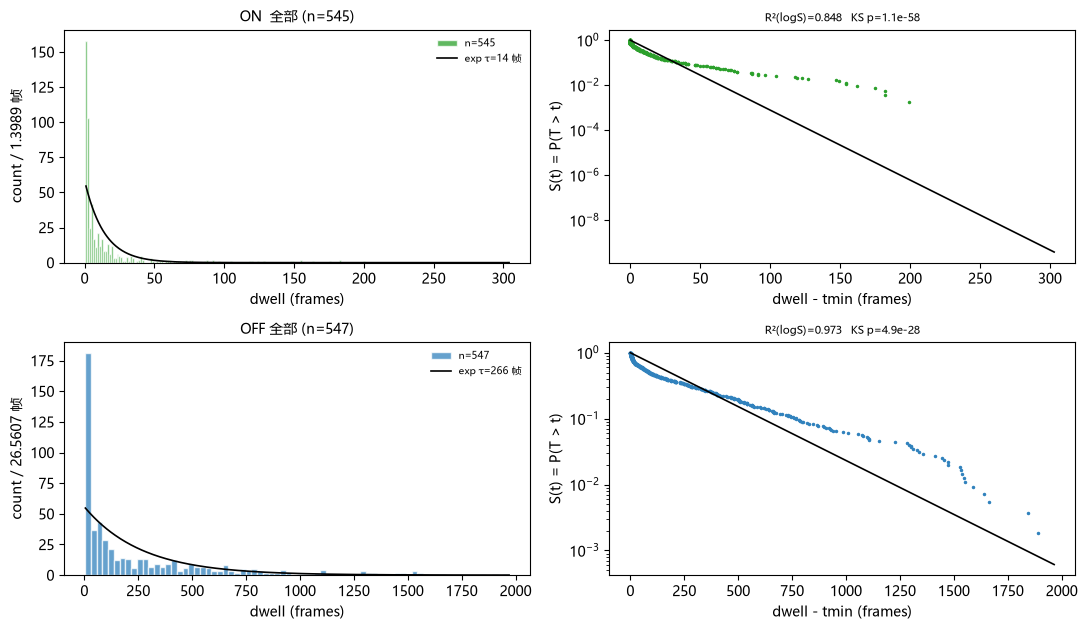

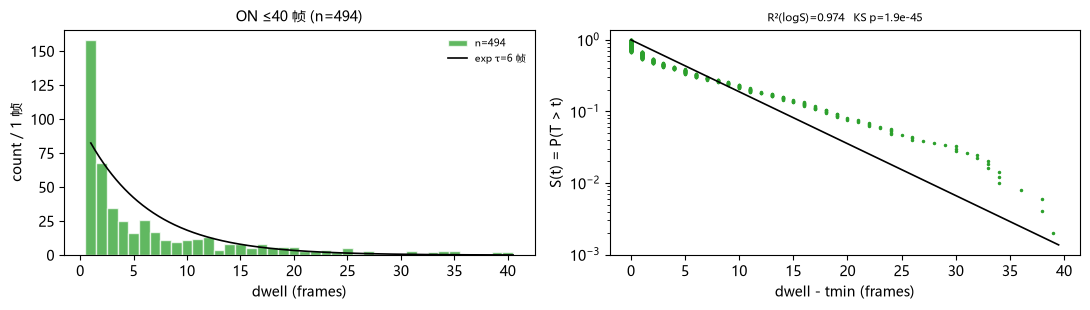

In [15]:
def plot_fit_row(ax_h, ax_s, x, r, tmin, color, name):
    x = np.asarray(x, float)
    w = max(1.0, r['tau'] / 10.0)
    edges = np.arange(tmin - 0.5, x.max() + w, w)
    ax_h.hist(x, bins=edges, color=color, alpha=0.75, edgecolor='white',
              label=f'n={x.size}')
    tt = np.linspace(tmin, edges[-1], 400)
    ax_h.plot(tt, x.size * w * np.exp(-(tt - tmin) / r['tau']) / r['tau'],
              'k-', lw=1.2, label=f'exp τ={r["tau"]:.0f} 帧')
    ax_h.set_xlabel('dwell (frames)')
    ax_h.set_ylabel(f'count / {w:g} 帧')
    ax_h.set_title(name, fontsize=10)
    ax_h.legend(fontsize=7, frameon=False)

    s = np.sort(x)
    surv = 1.0 - np.arange(1, s.size + 1) / s.size
    m = surv > 1e-3
    ax_s.semilogy(s[m] - tmin, surv[m], '.', ms=3, color=color)
    ax_s.plot(tt - tmin, np.exp(-(tt - tmin) / r['tau']), 'k-', lw=1.2)
    ax_s.set_xlabel('dwell - tmin (frames)')
    ax_s.set_ylabel('S(t) = P(T > t)')
    ax_s.set_title(f'R²(logS)={r["r2"]:.3f}   KS p={r["ks_p"]:.1e}',
                   fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
plot_fit_row(axes[0, 0], axes[0, 1], ON, fits['ON  全部'], EXPO_TMIN['on'],
             '#2ca02c', f'ON  全部 (n={ON.size})')
plot_fit_row(axes[1, 0], axes[1, 1], OFF, fits['OFF 全部'], EXPO_TMIN['off'],
             '#3182bd', f'OFF 全部 (n={OFF.size})')
fig.tight_layout()
plt.show()

# ON 去掉 >40 帧的长事件后单独看 (长 ON 不是单次闪烁, 会毁掉指数形状)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
plot_fit_row(axes[0], axes[1], ON[ON <= 40], fits['ON  ≤40 帧'],
             EXPO_TMIN['on'], '#2ca02c',
             f'ON ≤40 帧 (n={int((ON <= 40).sum())})')
fig.tight_layout()
plt.show()


## 拟合结论

- **OFF**：单指数描述得还算像（`R²(logS) ≈ 0.97`），但 `KS p` 极小、`χ²/dof` 远大于 1 ——
  上千个样本下任何形状偏差都会显著，说明它是"接近指数但不严格指数"。
- **ON**：`R²(logS)` 明显差，因为分布是**双峰**的：1 帧占 ~29%，另有一批 >40 帧的长事件。
  去掉长事件后 `R²` 好转，但 1 帧尖峰仍在。
- **τ 的绝对值不可直接引用**：观察窗口有限（1000/2000 帧）造成右截断，长 OFF 被切掉，
  τ 系统性偏小；OFF 还混着每条 trace 开头那段左截断的 OFF。

下一步要决定的方向：ON 的长事件是先剔掉还是单独建模；OFF 要不要按截断做 MLE
（用生存分析而不是 `mean - tmin`）。
